# Calculating the Impedance of a Graph

This notebook demonstrates how to calculate the equivalent resistance (impedance) of a resistor network represented as a graph.

## Graph Structure

Based on the reference image (with distortion to place source on left, drain on right):
- **4 nodes**: Node 0 (source), Node 1 (top-left), Node 2 (bottom-right), Node 3 (drain)
- **5 segments/edges**: Each edge represents a resistor

**Source**: Node 0 (left side, x < 0.1)  
**Drain**: Node 3 (right side, x > 0.9)

---
## Setup

In [ ]:
# Environment and path setup is handled in the next cell.


In [ ]:
import math
import sys
import os
import numpy as np

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

In [16]:
import matplotlib.pyplot as plt
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
from impedance_calculator import *

---
## Define Graph Data

This is a simple 4-node, 5-segment graph based on the reference image.
- Node 0: Source (left side)
- Node 1: Top-left
- Node 2: Bottom-right  
- Node 3: Drain (right side)

In [17]:
# ═══════════════════════════════════════════════════════════════════════
# GRAPH DEFINITION (Based on reference image)
# ═══════════════════════════════════════════════════════════════════════
print("="*70)
print("DEFINING GRAPH STRUCTURE")
print("="*70)

# Number of segments (edges)
N = 5

# ─────────────────────────────────────────────────────────────────────────
# SEGMENT ENDPOINTS (points_1 and points_2)
# Each segment i goes from points_1[i] to points_2[i]
# ─────────────────────────────────────────────────────────────────────────
# Segment 0: Node 3 (drain) ↔ Node 1 (top-left)
# Segment 1: Node 3 (drain) ↔ Node 2 (bottom-right)
# Segment 2: Node 1 (top-left) ↔ Node 2 (bottom-right)
# Segment 3: Node 3 (drain) ↔ Node 0 (source)
# Segment 4: Node 1 (top-left) ↔ Node 0 (source)

points_1 = [
    [0.95, 0.50],   # Segment 0: starts at drain (node 3)
    [0.95, 0.50],   # Segment 1: starts at drain (node 3)
    [0.35, 0.75],   # Segment 2: starts at node 1
    [0.95, 0.50],   # Segment 3: starts at drain (node 3)
    [0.35, 0.75],   # Segment 4: starts at node 1
]

points_2 = [
    [0.35, 0.75],   # Segment 0: ends at node 1
    [0.65, 0.25],   # Segment 1: ends at node 2
    [0.65, 0.25],   # Segment 2: ends at node 2
    [0.05, 0.50],   # Segment 3: ends at source (node 0)
    [0.05, 0.50],   # Segment 4: ends at source (node 0)
]

print(f"Number of segments: {N}")
for i in range(N):
    print(f"  Segment {i}: ({points_1[i][0]:.2f}, {points_1[i][1]:.2f}) -> ({points_2[i][0]:.2f}, {points_2[i][1]:.2f})")

DEFINING GRAPH STRUCTURE
Number of segments: 5
  Segment 0: (0.95, 0.50) -> (0.35, 0.75)
  Segment 1: (0.95, 0.50) -> (0.65, 0.25)
  Segment 2: (0.35, 0.75) -> (0.65, 0.25)
  Segment 3: (0.95, 0.50) -> (0.05, 0.50)
  Segment 4: (0.35, 0.75) -> (0.05, 0.50)


In [18]:
# ─────────────────────────────────────────────────────────────────────────
# DEFINE INTERSECTIONS MANUALLY
# For this pre-defined graph, we know exactly where the nodes are
# (identify_intersections looks for line crossings, but our segments share endpoints)
# ─────────────────────────────────────────────────────────────────────────

# Node positions (these are the endpoints where segments meet)
intersections = [
    [0.05, 0.50],   # Node 0: Source (left side)
    [0.35, 0.75],   # Node 1: Top-left
    [0.65, 0.25],   # Node 2: Bottom-right
    [0.95, 0.50],   # Node 3: Drain (right side)
]

# Graph: which segments meet at each node
# Segment 0: Node 1 <-> Node 3
# Segment 1: Node 2 <-> Node 3
# Segment 2: Node 1 <-> Node 2
# Segment 3: Node 0 <-> Node 3
# Segment 4: Node 0 <-> Node 1
graph = [
    [3, 4],      # Node 0: segments 3 and 4 meet here
    [0, 2, 4],   # Node 1: segments 0, 2, and 4 meet here
    [1, 2],      # Node 2: segments 1 and 2 meet here
    [0, 1, 3],   # Node 3: segments 0, 1, and 3 meet here
]

print(f"\nNumber of nodes (intersections): {len(intersections)}")
for i, (x, y) in enumerate(intersections):
    print(f"  Node {i}: ({x:.4f}, {y:.4f})")

print(f"\nGraph (segments at each node): {graph}")


Number of nodes (intersections): 4
  Node 0: (0.0500, 0.5000)
  Node 1: (0.3500, 0.7500)
  Node 2: (0.6500, 0.2500)
  Node 3: (0.9500, 0.5000)

Graph (segments at each node): [[3, 4], [0, 2, 4], [1, 2], [0, 1, 3]]


In [19]:
# ─────────────────────────────────────────────────────────────────────────
# VERIFY SEGMENT CONNECTIONS
# ─────────────────────────────────────────────────────────────────────────
print("\nVerifying segment connections:")
seg_connections = {}
for segs in graph:
    for s in segs:
        if s not in seg_connections:
            seg_connections[s] = set()
        for other in segs:
            if other != s:
                seg_connections[s].add(other)
                
for seg_id in sorted(seg_connections.keys()):
    print(f"  Segment {seg_id} connects to: {sorted(seg_connections[seg_id])}")


Verifying segment connections:
  Segment 0 connects to: [1, 2, 3, 4]
  Segment 1 connects to: [0, 2, 3]
  Segment 2 connects to: [0, 1, 4]
  Segment 3 connects to: [0, 1, 4]
  Segment 4 connects to: [0, 2, 3]


In [ ]:
# ─────────────────────────────────────────────────────────────────────────
# FIND BOUNDARY NODES (source and drain)
# ─────────────────────────────────────────────────────────────────────────
boundary_source = []
boundary_drain = []

for i in range(len(intersections)):
    if intersections[i][0] < 0.1:  # x < 0.1 -> source
        boundary_source.append(i)
    elif intersections[i][0] > 0.9:  # x > 0.9 -> drain
        boundary_drain.append(i)

if not boundary_source or not boundary_drain:
    raise ValueError(
        f"Strict boundary failed: source={len(boundary_source)}, drain={len(boundary_drain)}. No fallback allowed."
    )

print(f"\nBoundary nodes:")
print(f"  Source (x < 0.1): {boundary_source}")
for node in boundary_source:
    print(f"    Node {node}: ({intersections[node][0]:.4f}, {intersections[node][1]:.4f})")
print(f"  Drain (x > 0.9): {boundary_drain}")
for node in boundary_drain:
    print(f"    Node {node}: ({intersections[node][0]:.4f}, {intersections[node][1]:.4f})")

# Get boundary segments
source_segments = set()
drain_segments = set()
for node_idx in boundary_source:
    if node_idx < len(graph):
        source_segments.update(graph[node_idx])
for node_idx in boundary_drain:
    if node_idx < len(graph):
        drain_segments.update(graph[node_idx])

print(f"\nSource segments: {source_segments}")
print(f"Drain segments: {drain_segments}")


Boundary nodes:
  Source (x < 0.1): [0]
    Node 0: (0.0500, 0.5000)
  Drain (x > 0.9): [3]
    Node 3: (0.9500, 0.5000)

Source segments: {3, 4}
Drain segments: {0, 1, 3}


In [21]:
# ─────────────────────────────────────────────────────────────────────────
# FIND PATHS (using find_path from path_analysis.py)
# ─────────────────────────────────────────────────────────────────────────
path_nodes = []
path_pairs_of_lines = []
path_pairs_of_edges = []
all_path_perc = []
all_path_nodes = []

for i in boundary_source:
    do_not_check = 0
    for k in range(len(all_path_nodes)):
        if i in all_path_nodes[k]:
            do_not_check = 1
            break
    if do_not_check == 0:
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections, graph, i
        )
        path_nodes.append(nodes)
        path_pairs_of_lines.append(pair_of_lines)
        path_pairs_of_edges.append(pair_of_edges)
        all_path_perc.append(path_perc)
        all_path_nodes.append(nodes)

print(f"\nPath data structures:")
print(f"  Paths found: {len(path_nodes)}")
print(f"  Percolating: {sum(1 for p in all_path_perc if p == 1)}")

# Show path details
for i, nodes in enumerate(path_nodes):
    print(f"\n  Path {i}:")
    print(f"    path_nodes: {nodes}")
    print(f"    path_pairs_of_lines: {path_pairs_of_lines[i]}")
    print(f"    path_pairs_of_edges: {path_pairs_of_edges[i]}")
    print(f"    percolating: {all_path_perc[i]}")

valor de queue antes = deque([0])
valor de queue depois = deque([])
nós visitados {0}
valor de target edge = [3, 4]
valor de path_pairs_of_lines = [[3, 4]]
valor do i = 1
valor do current node = 0
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[0, 1]
valor do path_pairs_of_lines = [[3, 4], [0, 2, 4]]
valor do path_pairs_of_edges = [(0, 1)]
valor do i = 3
valor do current node = 0
valor da queue após append = deque([1, 3])
valor do path_pairs_of_nodes[0, 1, 3]
valor do path_pairs_of_lines = [[3, 4], [0, 2, 4], [0, 1, 3]]
valor do path_pairs_of_edges = [(0, 1), (0, 3)]
valor de queue antes = deque([1, 3])
valor de queue depois = deque([3])
nós visitados {0, 1}
valor de target edge = [0, 2, 4]
valor do i = 2
valor do current node = 1
valor da queue após append = deque([3, 2])
valor do path_pairs_of_nodes[0, 1, 3, 2]
valor do path_pairs_of_lines = [[3, 4], [0, 2, 4], [0, 1, 3], [1, 2]]
valor do path_pairs_of_edges = [(0, 1), (0, 3), (1, 2)]
valor de queue antes = deque

In [22]:
# ─────────────────────────────────────────────────────────────────────────
# BUILD SEGMENT-TO-NODES MAPPING
# Maps each segment to the pair of nodes it connects
# ─────────────────────────────────────────────────────────────────────────
segment_to_nodes = {}

# For each node, check which segments pass through it
for node_idx, segs in enumerate(graph):
    for seg in segs:
        if seg not in segment_to_nodes:
            segment_to_nodes[seg] = []
        segment_to_nodes[seg].append(node_idx)

# Convert lists to tuples (each segment connects exactly 2 nodes)
# If a segment has more than 2 nodes, keep only the first 2 (endpoints)
for seg in segment_to_nodes:
    nodes_list = segment_to_nodes[seg]
    if len(nodes_list) == 2:
        segment_to_nodes[seg] = tuple(sorted(nodes_list))
    elif len(nodes_list) > 2:
        print(f"  WARNING: Segment {seg} connects {len(nodes_list)} nodes: {nodes_list}")
        # Keep only the first 2 nodes (should be the actual endpoints)
        segment_to_nodes[seg] = tuple(sorted(nodes_list[:2]))
    else:
        print(f"  WARNING: Segment {seg} connects only {len(nodes_list)} node(s): {nodes_list}")
        # Pad with -1 to avoid errors
        segment_to_nodes[seg] = (nodes_list[0], -1) if len(nodes_list) == 1 else (-1, -1)

print(f"\nSegment to nodes mapping:")
for seg in sorted(segment_to_nodes.keys()):
    n1, n2 = segment_to_nodes[seg]
    print(f"  Segment {seg}: Node {n1} <-> Node {n2}")


Segment to nodes mapping:
  Segment 0: Node 1 <-> Node 3
  Segment 1: Node 2 <-> Node 3
  Segment 2: Node 1 <-> Node 2
  Segment 3: Node 0 <-> Node 3
  Segment 4: Node 0 <-> Node 1


---
## Visualize the Graph

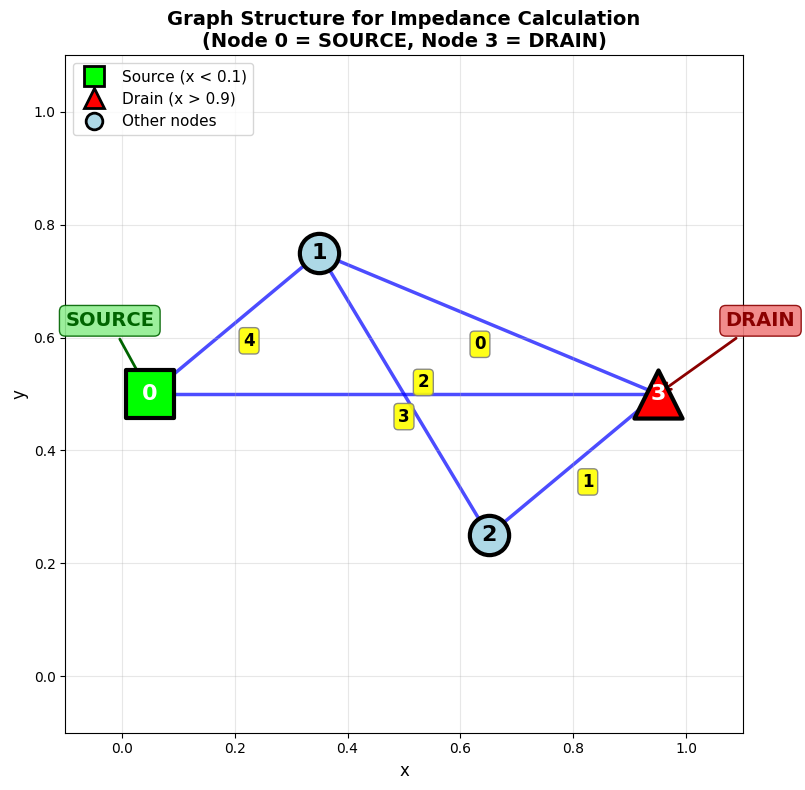

Source node: [0]
Drain node: [3]


In [23]:
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Draw segments
for i in range(N):
    x1, y1 = points_1[i]
    x2, y2 = points_2[i]
    ax.plot([x1, x2], [y1, y2], 'b-', linewidth=2.5, alpha=0.7, zorder=1)
    
    # Segment label at midpoint
    mid_x = (x1 + x2) / 2
    mid_y = (y1 + y2) / 2
    
    # Offset label perpendicular to segment
    dx = x2 - x1
    dy = y2 - y1
    length = np.sqrt(dx**2 + dy**2)
    offset = 0.04
    perp_x = -dy / length * offset
    perp_y = dx / length * offset
    
    ax.text(mid_x + perp_x, mid_y + perp_y, str(i), 
            fontsize=12, ha='center', va='center', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='yellow', edgecolor='gray', alpha=0.9))

# Draw nodes with clear source/drain identification
for node_id, (x, y) in enumerate(intersections):
    if node_id in boundary_source:
        color = 'lime'  # Bright green for source
        marker = 's'    # Square marker for source
        size = 1200
        label = f'{node_id}\nSOURCE'
    elif node_id in boundary_drain:
        color = 'red'   # Bright red for drain
        marker = '^'    # Triangle marker for drain
        size = 1200
        label = f'{node_id}\nDRAIN'
    else:
        color = 'lightblue'
        marker = 'o'    # Circle for other nodes
        size = 800
        label = str(node_id)
    
    ax.scatter(x, y, c=color, s=size, zorder=5, edgecolors='black', linewidths=3, marker=marker)
    ax.text(x, y, str(node_id), fontsize=16, fontweight='bold', 
            ha='center', va='center', zorder=6, color='white' if node_id in boundary_source or node_id in boundary_drain else 'black')
    
    # Add prominent label for source/drain
    if node_id in boundary_source:
        ax.annotate('SOURCE', xy=(x, y), xytext=(x - 0.15, y + 0.12),
                    fontsize=14, fontweight='bold', color='darkgreen',
                    arrowprops=dict(arrowstyle='->', color='darkgreen', lw=2),
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', edgecolor='darkgreen', alpha=0.9))
    elif node_id in boundary_drain:
        ax.annotate('DRAIN', xy=(x, y), xytext=(x + 0.12, y + 0.12),
                    fontsize=14, fontweight='bold', color='darkred',
                    arrowprops=dict(arrowstyle='->', color='darkred', lw=2),
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral', edgecolor='darkred', alpha=0.9))

ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.1)
ax.set_aspect('equal')

# Dynamic title based on actual boundary nodes
src_node = boundary_source[0] if boundary_source else '?'
drn_node = boundary_drain[0] if boundary_drain else '?'
ax.set_title(f'Graph Structure for Impedance Calculation\n(Node {src_node} = SOURCE, Node {drn_node} = DRAIN)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.grid(True, alpha=0.3)

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='lime', markersize=15, 
           markeredgecolor='black', markeredgewidth=2, label='Source (x < 0.1)'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='red', markersize=15, 
           markeredgecolor='black', markeredgewidth=2, label='Drain (x > 0.9)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightblue', markersize=12, 
           markeredgecolor='black', markeredgewidth=2, label='Other nodes'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

print("="*70)
print(f"Source node: {boundary_source}")
print(f"Drain node: {boundary_drain}")

---
## Calculate the Equivalent Resistance using `impedance_calculator`

Using the incidence matrix method (as described in the book, Figure 2.7):

1. Build incidence matrix $A$ (edges × nodes)
2. Laplacian $L = A^T \cdot A$
3. Reduce matrix $M$ (remove source/drain)
4. Boundary vector $\vec{b} = -L_{ib} \cdot V_{boundary}$
5. Solve $\vec{V} = M^{-1} \cdot \vec{b}$
6. Currents $I = -A \cdot \vec{V}$
7. Impedance $R = k / I_{total}$

In [24]:
# ═══════════════════════════════════════════════════════════════════════
# CALCULATE IMPEDANCE USING impedance_calculator MODULE
# ═══════════════════════════════════════════════════════════════════════
print("="*70)
print("CALCULATING IMPEDANCE - GRAPH 1")
print("="*70)

# Create calculator using the data structures we built
calc = ImpedanceCalculator(intersections, graph, segment_to_nodes)

# Calculate impedance with k = 1000 Ω (each resistor)
result = calc.calculate(k=1000, verbose=True)

# Print summary
print("\n")
calc.print_summary(result)

# Also test with different k values
print("\n" + "─"*70)
print("Testing with different k values:")
print("─"*70)
for k_value in [1, 10, 100, 1000]:
    R = calculate_path_impedance(intersections, graph, segment_to_nodes, k=k_value)
    print(f"  k = {k_value:4d} Ω  →  R = {R:.4f} Ω")

CALCULATING IMPEDANCE - GRAPH 1
Boundary vector b = [1. 0.]
Internal voltages V_internal = [0.4 0.2]
Full voltage vector V = [1.  0.4 0.2 0. ]
Currents I = [0.4 0.2 0.2 1.  0.6]
Total current at drain I_total = 1.6
Impedance R = k / I_total = 1000 / 1.6 = 625.0 Ω


IMPEDANCE CALCULATION SUMMARY

Graph structure:
  Number of nodes: 4
  Number of edges: 5
  Source node: 0 (x = 0.0500)
  Drain node: 3 (x = 0.9500)
  Internal nodes: [1, 2]

Matrices:
  Incidence matrix A: (5, 4)
  Laplacian L: (4, 4)
  Reduced matrix M: (2, 2)

Voltages:
  V_0 = 1.0000 (SOURCE)
  V_1 = 0.4000
  V_2 = 0.2000
  V_3 = 0.0000 (DRAIN)

Currents:
  I_0 = 0.4000
  I_1 = 0.2000
  I_2 = 0.2000
  I_3 = 1.0000
  I_4 = 0.6000

Results:
  k = 1000 Ω
  I_total = 1.6000 A
  Impedance R = 625.0000 Ω
             R = 0.6250 kΩ

──────────────────────────────────────────────────────────────────────
Testing with different k values:
──────────────────────────────────────────────────────────────────────
  k =    1 Ω  →  R = 0.